# ARQ-FEC PoC Analysis

Analyses one case at a time: set `GEOMETRY` below and run the whole notebook.
Run it once per case to compare them side by side:

- **nofec**: control case, plain SCHC Ack-on-Error (RFC 8724, Compound ACK RFC 9441), no FEC
- **stream**: ARQ-FEC, Stream Encoding Geometry (XOR parity)
- **matrix**: ARQ-FEC, Matrix Encoding Geometry (Reed-Solomon)

**Three outcomes per iteration:**
- Delivered without retransmission (with FEC: FEC sufficed)
- ARQ rescued it (first pass not enough, retransmission fixed it)
- Failed (the device gave up: Sender-Abort, or the session timed out)

---

In [81]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import glob

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 4)

## 1. Load Data

Loads every CSV of the selected case. Use `FILES` to pick specific runs.

In [82]:
GEOMETRY = "stream"   # "nofec" | "stream" | "matrix"
FILES = None          # or an explicit list, e.g. ["data/stats_2026-11-13_18-12-42.csv"]

PATTERN = f"data/stats-{GEOMETRY}_*.csv"

LABELS = {
    "nofec":  "No FEC (Ack-on-Error)",
    "stream": "ARQ-FEC Stream (XOR)",
    "matrix": "ARQ-FEC Matrix (RS)",
}
LABEL = LABELS[GEOMETRY]
FIRST_PASS = "No retx (no loss)" if GEOMETRY == "nofec" else "FEC sufficed"


def load_stats(files=None, pattern="data/stats_*.csv"):
    """Load one or more CSV files into a single DataFrame."""
    if files is None:
        files = sorted(glob.glob(pattern))
    if not files:
        raise FileNotFoundError("No CSV files found.")

    dfs = []
    for f in files:
        d = pd.read_csv(f)
        d["source_file"] = f
        dfs.append(d)

    df = pd.concat(dfs, ignore_index=True)
    print(f"{LABEL}: loaded {len(df):,} iterations across {len(files)} file(s)")
    return df


df = load_stats(FILES, PATTERN)
df.head(3)

ARQ-FEC Stream (XOR): loaded 400 iterations across 8 file(s)


,iteration,timestamp,cfg_loss_probability,cfg_allow_all1_loss,dev_regular_count,dev_regular_tx_attempts,dev_regular_lost,dev_all1_lost,dev_c1_recvd,dev_c0_recvd,...,srv_decodeable_before_retx,srv_decodeable,srv_rcs_ok,dev_aborted,srv_timed_out,srv_early_ack_sent,cfg_max_attempts,cfg_mtu,cfg_packet_bytes,source_file
0,1,2026-11-13 19:44:55.078429,0.0,True,6,6,0,0,1,0,...,True,True,True,False,False,0,3,11,39,data/stats-stream_2026-11-13_19-44-54.csv
1,2,2026-11-13 19:44:55.202642,0.0,True,6,6,0,0,1,0,...,True,True,True,False,False,0,3,11,39,data/stats-stream_2026-11-13_19-44-54.csv
2,3,2026-11-13 19:44:55.324433,0.0,True,6,6,0,0,1,0,...,True,True,True,False,False,0,3,11,39,data/stats-stream_2026-11-13_19-44-54.csv


## 2. Derived Columns

Outcome, retransmission cost, and message counts per iteration.

- **Uplinks** (device → server): every Regular Fragment, All-1 and ACK-REQ sent
  (including the ones lost on the channel), plus the Sender-Abort.
- **Downlinks** (server → device): every SCHC ACK sent (C=0, C=1, and the matrix early ACK).

In [83]:
# --- Outcome ---
# success_on_attempt: 0=failed, 1=no retransmission, 2=after retransmission(s)
cond = [
    (df["srv_rcs_ok"] == True) & (df["srv_retx_called"] == False),
    (df["srv_rcs_ok"] == True) & (df["srv_retx_called"] == True),
]
df["success_on_attempt"] = np.select(cond, [1, 2], default=0)

# --- Category ---
CATEGORIES = [FIRST_PASS, "ARQ rescued", "Failed"]
df["category"] = np.select(cond, CATEGORIES[:2], default="Failed")

# --- Retransmission cost ---
df["retx_frags"] = df["dev_regular_tx_attempts"] - df["dev_regular_count"]
df["actual_loss"] = df["dev_regular_lost"] / df["dev_regular_tx_attempts"]
df["all1_lost_scenario"] = df["dev_all1_lost"] > 0

# --- Messages ---
# dev_attempts = All-1 + ACK-REQ sent
df["uplinks"] = df["dev_regular_tx_attempts"] + df["dev_attempts"] + df["dev_aborted"].astype(int)
df["downlinks"] = df["srv_c0_sent"] + df["srv_c1_sent"] + df["srv_early_ack_sent"]

cols = ["iteration", "success_on_attempt", "category",
        "cfg_loss_probability", "cfg_allow_all1_loss", "cfg_max_attempts",
        "dev_regular_count", "dev_regular_tx_attempts", "retx_frags",
        "uplinks", "downlinks", "actual_loss", "all1_lost_scenario"]
df[cols].head(10)

,iteration,success_on_attempt,category,cfg_loss_probability,cfg_allow_all1_loss,cfg_max_attempts,dev_regular_count,dev_regular_tx_attempts,retx_frags,uplinks,downlinks,actual_loss,all1_lost_scenario
0,1,1,FEC sufficed,0.0,True,3,6,6,0,7,1,0.0,False
1,2,1,FEC sufficed,0.0,True,3,6,6,0,7,1,0.0,False
2,3,1,FEC sufficed,0.0,True,3,6,6,0,7,1,0.0,False
3,4,1,FEC sufficed,0.0,True,3,6,6,0,7,1,0.0,False
4,5,1,FEC sufficed,0.0,True,3,6,6,0,7,1,0.0,False
5,6,1,FEC sufficed,0.0,True,3,6,6,0,7,1,0.0,False
6,7,1,FEC sufficed,0.0,True,3,6,6,0,7,1,0.0,False
7,8,1,FEC sufficed,0.0,True,3,6,6,0,7,1,0.0,False
8,9,1,FEC sufficed,0.0,True,3,6,6,0,7,1,0.0,False
9,10,1,FEC sufficed,0.0,True,3,6,6,0,7,1,0.0,False


## 3. Overall Summary

In [84]:
total = len(df)
print(f"=== {LABEL} ===")
print(f"Total iterations        : {total}")
print(f"Config loss probability : {sorted(df['cfg_loss_probability'].unique())}")
print(f"Allow All-1 loss        : {df['cfg_allow_all1_loss'].unique()}")
print(f"MAX_ATTEMPTS            : {df['cfg_max_attempts'].unique()}")
print(f"SCHC packet / MTU       : {df['cfg_packet_bytes'].unique()} B / {df['cfg_mtu'].unique()} B")
print(f"Fragments per pass      : {df['dev_regular_count'].unique()}")
if df["cfg_loss_probability"].nunique() > 1:
    print()
    print("!! Several loss probabilities mixed: these totals average over them.")
    print("!! Use section 5 (per loss probability) for figures to present.")
print()
print(f"Success rate            : {df['success_on_attempt'].gt(0).mean():.1%}")
print(f"  └ No retransmission   : {(df['success_on_attempt']==1).mean():.1%}")
print(f"  └ After retx          : {(df['success_on_attempt']==2).mean():.1%}")
print(f"Failure rate            : {(df['success_on_attempt']==0).mean():.1%}")
print()
print(f"Avg uplinks per run     : {df['uplinks'].mean():.2f}")
print(f"Avg downlinks per run   : {df['downlinks'].mean():.2f}")
print()
print("--- Category breakdown ---")
print(df["category"].value_counts().reindex(CATEGORIES, fill_value=0).to_string())

=== ARQ-FEC Stream (XOR) ===
Total iterations        : 400
Config loss probability : [np.float64(0.0), np.float64(0.05), np.float64(0.1), np.float64(0.2), np.float64(0.3), np.float64(0.4), np.float64(0.5), np.float64(0.7)]
Allow All-1 loss        : [ True]
MAX_ATTEMPTS            : [3]
SCHC packet / MTU       : [39] B / [11] B
Fragments per pass      : [6]

!! Several loss probabilities mixed: these totals average over them.
!! Use section 5 (per loss probability) for figures to present.

Success rate            : 86.0%
  └ No retransmission   : 62.5%
  └ After retx          : 23.5%
Failure rate            : 14.0%

Avg uplinks per run     : 9.16
Avg downlinks per run   : 1.33

--- Category breakdown ---
category
FEC sufficed    250
ARQ rescued      94
Failed           56


## 4. FEC Effectiveness

**FEC sufficed** (no FEC: *No retx (no loss)*) = the packet was delivered from the
first pass alone, without any retransmission. With FEC, the parity recovered the
lost symbols; without FEC, this only happens when no fragment was lost.

**ARQ rescued** = the first pass was not enough; after a C=0, the retransmitted
tiles completed the packet.

**Failed** = the packet was not delivered within `MAX_ATTEMPTS`.

  FEC sufficed         250  ( 62.5%)
  ARQ rescued           94  ( 23.5%)
  Failed                56  ( 14.0%)


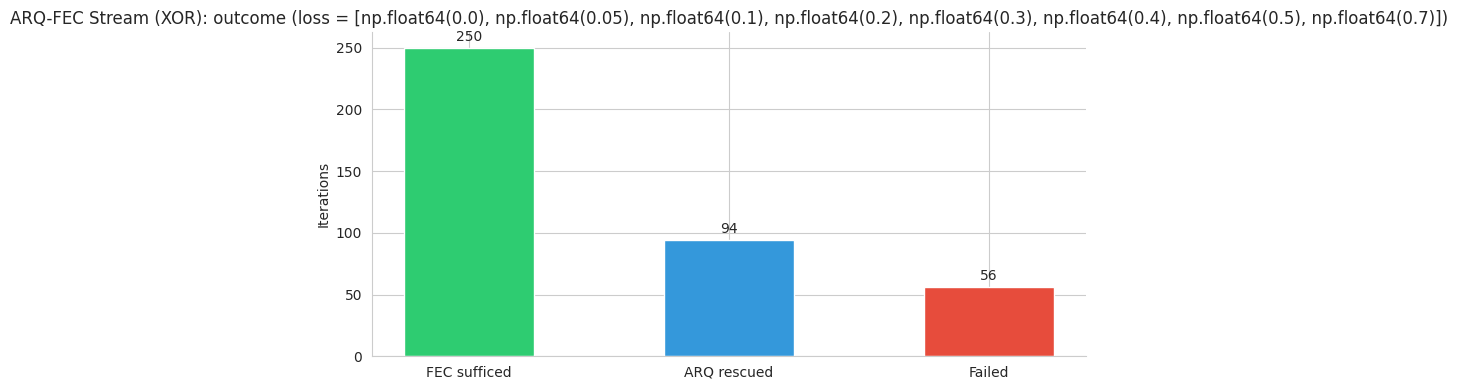

In [85]:
cats = df["category"].value_counts().reindex(CATEGORIES, fill_value=0)
for label, count in cats.items():
    print(f"  {label:18s}  {count:4d}  ({count/total:6.1%})")

fig, ax = plt.subplots()
colors = {FIRST_PASS: "#2ecc71", "ARQ rescued": "#3498db", "Failed": "#e74c3c"}
bars = ax.bar(cats.index, cats.values, color=[colors[c] for c in cats.index],
              edgecolor="white", width=0.5)
ax.bar_label(bars, fmt="%d", padding=3)
ax.set_ylabel("Iterations")
ax.set_title(f"{LABEL}: outcome (loss = {sorted(df['cfg_loss_probability'].unique())})")
sns.despine()
plt.tight_layout()
plt.show()

## 5. Breakdown by Loss Probability

In [86]:
grouped = df.groupby("cfg_loss_probability").agg(
    total=("success_on_attempt", "count"),
    success_rate=("success_on_attempt", lambda x: x.gt(0).mean()),
    no_retx=("category", lambda x: (x == FIRST_PASS).mean()),
    arq_rescue=("category", lambda x: (x == "ARQ rescued").mean()),
    failed=("category", lambda x: (x == "Failed").mean()),
    avg_uplinks=("uplinks", "mean"),
    avg_downlinks=("downlinks", "mean"),
    avg_retx_frags=("retx_frags", "mean"),
    avg_actual_loss=("actual_loss", "mean"),
    all1_lost_rate=("all1_lost_scenario", "mean"),
).round(4)
print(LABEL)
grouped

ARQ-FEC Stream (XOR)


,total,success_rate,no_retx,arq_rescue,failed,avg_uplinks,avg_downlinks,avg_retx_frags,avg_actual_loss,all1_lost_rate
cfg_loss_probability,,,,,,,,,,
0.00,50,1.00,1.00,0.00,0.00,7.00,1.00,0.00,0.0000,0.00
0.05,50,1.00,0.96,0.04,0.00,7.16,1.04,0.08,0.0367,0.04
0.10,50,1.00,0.94,0.06,0.00,7.26,1.06,0.12,0.1167,0.08
0.20,50,0.96,0.74,0.22,0.04,8.16,1.20,0.60,0.1992,0.22
0.30,50,0.98,0.64,0.34,0.02,9.10,1.38,1.18,0.2930,0.34
0.40,50,0.86,0.44,0.42,0.14,10.12,1.54,1.84,0.3664,0.38
0.50,50,0.78,0.26,0.52,0.22,10.54,1.58,2.12,0.4390,0.34
0.70,50,0.30,0.02,0.28,0.70,13.92,1.88,4.30,0.7142,0.58


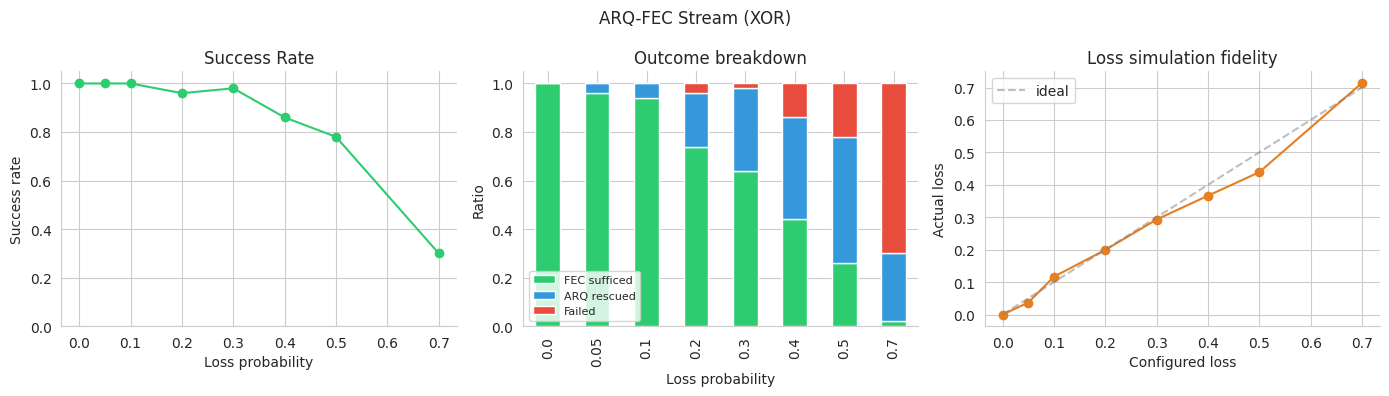

In [87]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
fig.suptitle(LABEL)

# Success rate
axes[0].plot(grouped.index, grouped["success_rate"], "o-", color="#2ecc71")
axes[0].set_xlabel("Loss probability")
axes[0].set_ylabel("Success rate")
axes[0].set_ylim(0, 1.05)
axes[0].set_title("Success Rate")

# Stacked bar: no retx vs ARQ vs Failed
grouped[["no_retx", "arq_rescue", "failed"]].plot.bar(
    ax=axes[1], stacked=True,
    color=["#2ecc71", "#3498db", "#e74c3c"],
    edgecolor="white", legend=False
)
axes[1].legend([FIRST_PASS, "ARQ rescued", "Failed"], fontsize=8, loc="lower left")
axes[1].set_xlabel("Loss probability")
axes[1].set_ylabel("Ratio")
axes[1].set_ylim(0, 1.05)
axes[1].set_title("Outcome breakdown")

# Actual vs configured loss
axes[2].plot(grouped.index, grouped["avg_actual_loss"], "o-", color="#e67e22")
axes[2].plot(grouped.index, grouped.index, "--", color="gray", alpha=0.5, label="ideal")
axes[2].set_xlabel("Configured loss")
axes[2].set_ylabel("Actual loss")
axes[2].set_title("Loss simulation fidelity")
axes[2].legend()

sns.despine()
plt.tight_layout()
plt.show()

## 6. Downlinks (server → device)

Downlinks are scarce in LPWANs (duty cycle, receive windows). Every SCHC ACK
counts: C=0 (retransmission request), C=1 (session end), and, in the matrix
geometry only, the early "enough symbols" ACK. Without loss the minimum is one
downlink (C=1); FEC aims to keep it there as loss grows.

ARQ-FEC Stream (XOR)


,avg_downlinks,avg_c0,avg_c1,avg_early_ack,max_downlinks,runs_with_c0
cfg_loss_probability,,,,,,
0.00,1.00,0.00,1.00,0.0,1,0.00
0.05,1.04,0.04,1.00,0.0,2,0.04
0.10,1.06,0.06,1.00,0.0,2,0.06
0.20,1.20,0.24,0.96,0.0,2,0.24
0.30,1.38,0.40,0.98,0.0,3,0.34
0.40,1.54,0.68,0.86,0.0,3,0.50
0.50,1.58,0.80,0.78,0.0,3,0.64
0.70,1.88,1.58,0.30,0.0,3,0.84


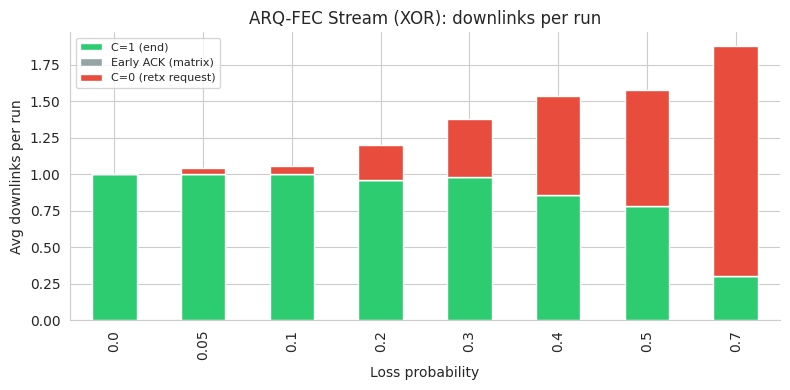

In [88]:
downlinks = df.groupby("cfg_loss_probability").agg(
    avg_downlinks=("downlinks", "mean"),
    avg_c0=("srv_c0_sent", "mean"),
    avg_c1=("srv_c1_sent", "mean"),
    avg_early_ack=("srv_early_ack_sent", "mean"),
    max_downlinks=("downlinks", "max"),
    runs_with_c0=("srv_c0_sent", lambda x: x.gt(0).mean()),
).round(3)
print(LABEL)
display(downlinks)

fig, ax = plt.subplots()
downlinks[["avg_c1", "avg_early_ack", "avg_c0"]].plot.bar(
    ax=ax, stacked=True, color=["#2ecc71", "#95a5a6", "#e74c3c"], edgecolor="white"
)
ax.legend(["C=1 (end)", "Early ACK (matrix)", "C=0 (retx request)"], fontsize=8)
ax.set_xlabel("Loss probability")
ax.set_ylabel("Avg downlinks per run")
ax.set_title(f"{LABEL}: downlinks per run")
sns.despine()
plt.tight_layout()
plt.show()

## 7. All-1 Loss Scenarios

When the All-1 is lost, the server never gets the RCS (nor the residual bits).
The device times out and resends the All-1 (each All-1 / ACK-REQ sent
counts towards `MAX_ATTEMPTS`).

In [89]:
all1_lost = df[df["all1_lost_scenario"]]
all1_ok = df[~df["all1_lost_scenario"]]

if len(all1_lost) > 0:
    print(f"{LABEL} - All-1 lost: {len(all1_lost)} / {len(df)} iterations")
    print()
    print("  All-1 never lost:")
    print(f"    Success: {all1_ok['success_on_attempt'].gt(0).mean():.1%}")
    print(f"    Retx needed: {all1_ok['srv_retx_called'].mean():.1%}")
    print()
    print("  All-1 lost at least once:")
    print(f"    Success: {all1_lost['success_on_attempt'].gt(0).mean():.1%}")
    print(f"    Retx needed: {all1_lost['srv_retx_called'].mean():.1%}")
    print()
    print("  All-1 loss scenario rows:")
    display(all1_lost[["iteration", "cfg_loss_probability",
                       "success_on_attempt", "category",
                       "srv_retx_called", "dev_attempts", "source_file"]])
else:
    print("No All-1 loss scenarios in this dataset.")
    print("(Set ALLOW_ALL1_LOSS = True with sufficient iterations to see them.)")

ARQ-FEC Stream (XOR) - All-1 lost: 99 / 400 iterations

  All-1 never lost:
    Success: 95.0%
    Retx needed: 28.6%

  All-1 lost at least once:
    Success: 58.6%
    Retx needed: 47.5%

  All-1 loss scenario rows:


,iteration,cfg_loss_probability,success_on_attempt,category,srv_retx_called,dev_attempts,source_file
64,15,0.05,1,FEC sufficed,False,2,data/stats-stream_2026-11-13_19-51-10.csv
89,40,0.05,1,FEC sufficed,False,2,data/stats-stream_2026-11-13_19-51-10.csv
104,5,0.10,1,FEC sufficed,False,2,data/stats-stream_2026-11-13_19-51-42.csv
108,9,0.10,1,FEC sufficed,False,2,data/stats-stream_2026-11-13_19-51-42.csv
135,36,0.10,1,FEC sufficed,False,2,data/stats-stream_2026-11-13_19-51-42.csv
...,...,...,...,...,...,...,...
388,39,0.70,0,Failed,False,3,data/stats-stream_2026-11-13_20-21-30.csv
391,42,0.70,2,ARQ rescued,True,3,data/stats-stream_2026-11-13_20-21-30.csv
393,44,0.70,0,Failed,False,3,data/stats-stream_2026-11-13_20-21-30.csv
396,47,0.70,0,Failed,False,3,data/stats-stream_2026-11-13_20-21-30.csv


## 8. Uplink / Retransmission Overhead

Fragments per pass differ between cases (FEC adds parity; the packet and MTU may
differ too), so compare total uplinks, not only retransmissions.

In [90]:
print(f"{LABEL} - average per iteration:")
print(f"  Fragments per pass     : {df['dev_regular_count'].mean():.1f}")
print(f"  Regular frags sent     : {df['dev_regular_tx_attempts'].mean():.1f}")
print(f"  Retransmitted frags    : {df['retx_frags'].mean():.1f}")
print(f"  Lost regular frags     : {df['dev_regular_lost'].mean():.1f}")
print(f"  All uplinks            : {df['uplinks'].mean():.1f}")
print()
print("By loss probability:")
overhead = df.groupby("cfg_loss_probability").agg({
    "dev_regular_count": "mean",
    "dev_regular_tx_attempts": "mean",
    "retx_frags": "mean",
    "dev_regular_lost": "mean",
    "uplinks": "mean",
}).round(2)
overhead

ARQ-FEC Stream (XOR) - average per iteration:
  Fragments per pass     : 6.0
  Regular frags sent     : 7.3
  Retransmitted frags    : 1.3
  Lost regular frags     : 2.4
  All uplinks            : 9.2

By loss probability:


,dev_regular_count,dev_regular_tx_attempts,retx_frags,dev_regular_lost,uplinks
cfg_loss_probability,,,,,
0.00,6.0,6.00,0.00,0.00,7.00
0.05,6.0,6.08,0.08,0.24,7.16
0.10,6.0,6.12,0.12,0.74,7.26
0.20,6.0,6.60,0.60,1.42,8.16
0.30,6.0,7.18,1.18,2.30,9.10
0.40,6.0,7.84,1.84,3.16,10.12
0.50,6.0,8.12,2.12,3.76,10.54
0.70,6.0,10.30,4.30,7.44,13.92


## 9. Failure Drill-Down

Rows where success_on_attempt == 0.

In [91]:
failures = df[df["success_on_attempt"] == 0]
if len(failures) > 0:
    print(f"{LABEL} - failure count: {len(failures)}")
    display(failures[["iteration", "cfg_loss_probability",
                      "dev_aborted", "srv_timed_out", "dev_attempts",
                      "srv_all1_recvd", "srv_c0_sent", "all1_lost_scenario",
                      "dev_regular_lost", "dev_regular_tx_attempts",
                      "source_file"]])
else:
    print("No failures.")

ARQ-FEC Stream (XOR) - failure count: 56


,iteration,cfg_loss_probability,dev_aborted,srv_timed_out,dev_attempts,srv_all1_recvd,srv_c0_sent,all1_lost_scenario,dev_regular_lost,dev_regular_tx_attempts,source_file
172,23,0.2,True,False,3,False,0,True,2,6,data/stats-stream_2026-11-13_19-52-39.csv
182,33,0.2,True,False,3,True,1,True,3,6,data/stats-stream_2026-11-13_19-52-39.csv
207,8,0.3,True,False,3,False,0,True,2,6,data/stats-stream_2026-11-13_19-58-12.csv
254,5,0.4,True,False,3,False,0,True,2,6,data/stats-stream_2026-11-13_20-10-06.csv
258,9,0.4,True,False,3,False,0,True,2,6,data/stats-stream_2026-11-13_20-10-06.csv
260,11,0.4,True,False,3,True,1,True,2,6,data/stats-stream_2026-11-13_20-10-06.csv
277,28,0.4,True,False,3,True,1,True,4,6,data/stats-stream_2026-11-13_20-10-06.csv
286,37,0.4,True,False,3,True,2,True,5,9,data/stats-stream_2026-11-13_20-10-06.csv
287,38,0.4,True,False,3,False,0,True,2,6,data/stats-stream_2026-11-13_20-10-06.csv
294,45,0.4,True,False,3,True,1,True,2,6,data/stats-stream_2026-11-13_20-10-06.csv


## 10. Config Distribution

Quick check: what configurations are present in the loaded dataset?

In [92]:
print(f"{LABEL} - configurations present:")
group_cols = ["cfg_loss_probability", "cfg_allow_all1_loss", "cfg_max_attempts",
              "cfg_packet_bytes", "cfg_mtu"]
configs = df.groupby(group_cols).size().reset_index(name="iterations")
configs

ARQ-FEC Stream (XOR) - configurations present:


,cfg_loss_probability,cfg_allow_all1_loss,cfg_max_attempts,cfg_packet_bytes,cfg_mtu,iterations
0,0.00,True,3,39,11,50
1,0.05,True,3,39,11,50
2,0.10,True,3,39,11,50
3,0.20,True,3,39,11,50
4,0.30,True,3,39,11,50
5,0.40,True,3,39,11,50
6,0.50,True,3,39,11,50
7,0.70,True,3,39,11,50


## 11. Source Files

Confirm which files contributed data.

In [93]:
print(df["source_file"].value_counts().to_string())

source_file
data/stats-stream_2026-11-13_19-44-54.csv    50
data/stats-stream_2026-11-13_19-51-10.csv    50
data/stats-stream_2026-11-13_19-51-42.csv    50
data/stats-stream_2026-11-13_19-52-39.csv    50
data/stats-stream_2026-11-13_19-58-12.csv    50
data/stats-stream_2026-11-13_20-10-06.csv    50
data/stats-stream_2026-11-13_20-14-05.csv    50
data/stats-stream_2026-11-13_20-21-30.csv    50
